# Faut-il acheter cette parcelle pour construire ?

Un particulier, un promoteur ou un constructeur de maisons trouve un terrain à vendre. Avant de signer, il doit répondre à trois questions :

1. **Peut-on construire dessus ?** (règles d'urbanisme, risques naturels, forme du terrain)
2. **Combien vaut-il vraiment ?** (le prix demandé est-il cohérent avec le marché ?)
3. **Combien coûtera la construction en plus ?** (zone inondable, sol argileux, pente, raccordements)

Ce notebook construit un outil d'aide à la décision qui répond à ces trois questions avec du machine learning, puis les combine en une recommandation : **Acheter**, **Négocier** ou **Éviter**, avec un prix maximum conseillé.

**Données** : 6 000 parcelles **simulées** dont les variables reprennent les données ouvertes françaises (DVF pour les prix, PLU pour le zonage, Géorisques pour l'inondation et les argiles, IGN pour la pente). Le module `src/dvf.py` permet de recaler les prix sur les vraies ventes DVF d'un département (voir le README).

In [1]:
import sys
sys.path.append("..")

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import roc_auc_score, brier_score_loss, mean_absolute_error

from src import model as M
from src.simulation import generer_parcelles

FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
RES = Path("../results"); RES.mkdir(exist_ok=True)

# Palette (bleu, orange, vert d'eau, jaune) et style sobre
BLEU, ORANGE, AQUA, JAUNE, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#b5b4ae", "axes.titleweight": "bold", "axes.titlesize": 11,
})

chemin = Path("../data/parcelles.csv")
if not chemin.exists():
    generer_parcelles().to_csv(chemin, index=False)
df = pd.read_csv(chemin)
print(df.shape)
df.head()

(6000, 19)


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,id_parcelle,commune,distance_centre_km,prix_m2_commune,surface_m2,zone_plu,distance_cours_eau_m,zone_inondable,alea_argiles,pente_pct,viabilise,largeur_facade_m,distance_ecole_km,distance_gare_km,constructible,valeur_marche,prix_demande,surcouts,bonne_affaire
0,P00000,Commune_00,0.0,269.0,484.0,AU,5892.0,non,moyen,10.1,True,14.1,0.68,1.7,0,1100.0,1000.0,15200.0,0
1,P00001,Commune_05,7.0,214.0,364.0,U,4993.0,non,faible,3.0,True,18.9,1.14,2.9,1,109100.0,123400.0,0.0,0
2,P00002,Commune_01,3.6,231.0,572.0,U,754.0,non,faible,7.7,True,21.9,0.67,1.3,1,139700.0,160400.0,4900.0,0
3,P00003,Commune_25,20.3,122.0,1191.0,U,2087.0,non,moyen,6.1,True,31.5,0.72,0.7,0,4000.0,4400.0,8000.0,0
4,P00004,Commune_01,3.6,231.0,488.0,A,1311.0,non,faible,1.5,False,21.1,3.24,2.1,0,1100.0,1300.0,20000.0,0


## 1. Les données

| Variable | Source réelle équivalente | Rôle |
|---|---|---|
| `surface_m2`, `prix_demande` | annonce / DVF | taille et prix du terrain |
| `prix_m2_commune` | DVF (médiane des terrains à bâtir vendus dans la commune) | niveau de prix local |
| `zone_plu` | Géoportail de l'urbanisme : U (urbaine), AU (à urbaniser), A (agricole), N (naturelle) | règle principale de constructibilité |
| `zone_inondable` | Géorisques / PPRI : rouge (interdit), bleue (constructible sous conditions) | risque et surcoût |
| `alea_argiles` | Géorisques : retrait-gonflement des argiles | fissures, fondations renforcées |
| `pente_pct` | IGN RGE ALTI | terrassement |
| `viabilise` | annonce / mairie | raccordement eau, électricité, égouts |
| `largeur_facade_m` | cadastre | un terrain trop étroit est difficile à bâtir |
| distances (centre, école, gare, cours d'eau) | BPE Insee, BD TOPO | attractivité |

Deux variables servent de **vérité terrain** pour évaluer l'outil : `constructible` (le permis a-t-il été accordé ?) et `valeur_marche` (le prix auquel le terrain se revend vraiment).

In [2]:
print(f"Parcelles constructibles : {df['constructible'].mean():.0%}")
print(f"Bonnes affaires (constructible ET prix + surcoûts < valeur) : {df['bonne_affaire'].mean():.0%}")
df.groupby("zone_plu")["constructible"].agg(["mean", "size"]).rename(columns={"mean": "taux_constructible", "size": "nb"}).round(2)

Parcelles constructibles : 52%
Bonnes affaires (constructible ET prix + surcoûts < valeur) : 17%


,taux_constructible,nb
zone_plu,,
A,0.02,1271
AU,0.64,895
N,0.02,906
U,0.86,2928


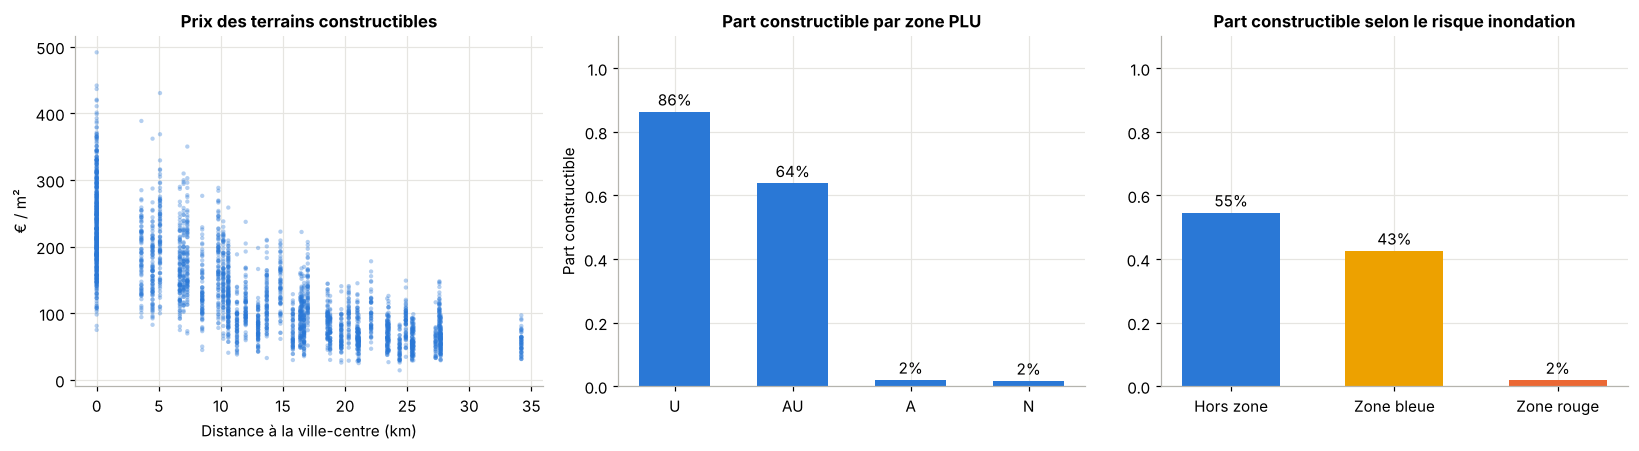

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))

c = df[df["constructible"] == 1]
ax[0].scatter(c["distance_centre_km"], c["valeur_marche"] / c["surface_m2"], s=8, alpha=0.35, color=BLEU, edgecolor="none")
ax[0].set(title="Prix des terrains constructibles", xlabel="Distance à la ville-centre (km)", ylabel="€ / m²")

taux = df.groupby("zone_plu")["constructible"].mean().reindex(["U", "AU", "A", "N"])
ax[1].bar(taux.index, taux.values, color=BLEU, width=0.6)
for i, v in enumerate(taux.values):
    ax[1].text(i, v + 0.02, f"{v:.0%}", ha="center", fontsize=10)
ax[1].set(title="Part constructible par zone PLU", ylim=(0, 1.1), ylabel="Part constructible")

taux_i = df.groupby("zone_inondable")["constructible"].mean().reindex(["non", "bleue", "rouge"])
ax[2].bar(["Hors zone", "Zone bleue", "Zone rouge"], taux_i.values, color=[BLEU, JAUNE, ORANGE], width=0.6)
for i, v in enumerate(taux_i.values):
    ax[2].text(i, v + 0.02, f"{v:.0%}", ha="center", fontsize=10)
ax[2].set(title="Part constructible selon le risque inondation", ylim=(0, 1.1))
plt.tight_layout(); plt.savefig(FIG / "exploration.png", bbox_inches="tight"); plt.show()

**Ce qu'on retient**
- Le prix au m² chute avec l'éloignement de la ville-centre : la localisation domine le marché.
- La zone PLU est déterminante : un terrain en zone A ou N n'est presque jamais constructible, quel que soit son prix.
- En zone rouge du PPRI, construire est interdit ; en zone bleue, c'est possible mais plus cher et plus souvent refusé.

**Le piège classique** : certains vendeurs affichent un terrain agricole au prix d'un terrain à bâtir. Regardons ces annonces.

In [4]:
non_c = df[df["constructible"] == 0]
ratio = non_c["prix_demande"] / non_c["valeur_marche"]
print(f"Terrains non constructibles affichés à plus de 5 fois leur valeur : {(ratio > 5).mean():.0%}")
print(f"Perte moyenne si on les achète : {(non_c.loc[ratio > 5, 'prix_demande'] - non_c.loc[ratio > 5, 'valeur_marche']).mean():,.0f} €".replace(",", " "))

Terrains non constructibles affichés à plus de 5 fois leur valeur : 35%
Perte moyenne si on les achète : 67 607 €


## 2. Découpage des données

- **Entraînement** (60 %) : apprendre les modèles.
- **Validation** (20 %) : choisir la règle de décision (marge minimale exigée).
- **Test** (20 %) : évaluation finale, jamais utilisée avant la toute fin.

In [5]:
train, test = train_test_split(df, test_size=0.2, random_state=0, stratify=df["bonne_affaire"])
train, val = train_test_split(train, test_size=0.25, random_state=0, stratify=train["bonne_affaire"])
print(len(train), len(val), len(test))

3600 1200 1200


## 3. Question 1 : peut-on construire ?

Classification binaire de `constructible`. On compare une **régression logistique** (simple, lisible) à **XGBoost** (arbres de décision boostés, capte les interactions).

Deux métriques :
- **AUC** : capacité à classer les terrains du plus sûr au plus douteux (1 = parfait, 0,5 = hasard).
- **Score de Brier** : qualité des probabilités (plus c'est bas, mieux c'est). Important ici, car la probabilité entre directement dans le calcul du gain attendu.

On n'utilise **pas** le prix demandé comme variable : le modèle doit juger le terrain, pas croire le vendeur.

In [6]:
Xtr, Xva, Xte = M.preparer(train), M.preparer(val), M.preparer(test)
cv = StratifiedKFold(5, shuffle=True, random_state=0)

lignes = []
for nom, fabrique in [("Régression logistique", M.classifieur_logistique), ("XGBoost", M.classifieur_xgb)]:
    auc_cv = cross_val_score(fabrique(), Xtr, train["constructible"], cv=cv, scoring="roc_auc")
    m = fabrique().fit(Xtr, train["constructible"])
    p = m.predict_proba(Xva)[:, 1]
    lignes.append({"modèle": nom, "AUC CV (train)": f"{auc_cv.mean():.3f} ± {auc_cv.std():.3f}",
                   "AUC validation": round(roc_auc_score(val["constructible"], p), 3),
                   "Brier validation": round(brier_score_loss(val["constructible"], p), 3)})
comparaison_clf = pd.DataFrame(lignes)
comparaison_clf

,modèle,AUC CV (train),AUC validation,Brier validation
0,Régression logistique,0.928 ± 0.012,0.920,0.093
1,XGBoost,0.922 ± 0.011,0.919,0.096


Les deux modèles font jeu égal. Les règles d'urbanisme sont presque des seuils simples (zone U/AU, hors zone rouge, pente raisonnable), qu'une régression logistique capte très bien. **On garde la régression logistique** : à performance égale, le modèle le plus simple et le plus explicable l'emporte.

L'AUC ne monte pas à 1 : une partie des refus de permis vient de contraintes absentes des données (servitudes, avis de l'architecte des Bâtiments de France, recours de voisins). C'est pour cela qu'en pratique on demande toujours un **certificat d'urbanisme opérationnel** avant d'acheter.

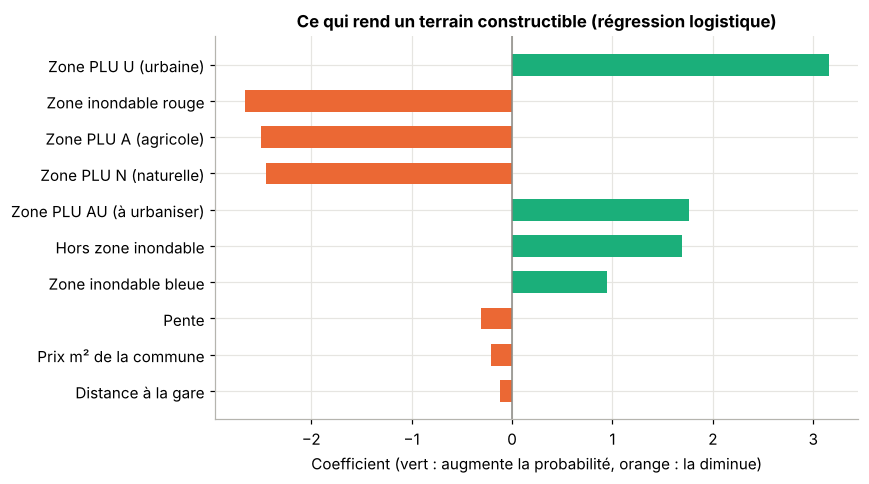

In [7]:
clf = M.classifieur_logistique().fit(Xtr, train["constructible"])
coefs = pd.Series(clf.named_steps["clf"].coef_[0], index=clf.named_steps["prep"].get_feature_names_out())
noms = {"zone_plu_U": "Zone PLU U (urbaine)", "zone_plu_AU": "Zone PLU AU (à urbaniser)", "zone_plu_A": "Zone PLU A (agricole)",
        "zone_plu_N": "Zone PLU N (naturelle)", "zone_inondable_rouge": "Zone inondable rouge", "zone_inondable_bleue": "Zone inondable bleue",
        "zone_inondable_non": "Hors zone inondable", "pente_pct": "Pente", "largeur_facade_m": "Largeur de façade",
        "viabilise": "Viabilisé", "distance_cours_eau_m": "Distance au cours d'eau", "surface_m2": "Surface",
        "distance_centre_km": "Distance au centre", "prix_m2_commune": "Prix m² de la commune",
        "distance_ecole_km": "Distance à l'école", "distance_gare_km": "Distance à la gare",
        "alea_argiles_faible": "Argiles : aléa faible", "alea_argiles_moyen": "Argiles : aléa moyen", "alea_argiles_fort": "Argiles : aléa fort"}
top = coefs.reindex(coefs.abs().sort_values().index)[-10:]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh([noms.get(i, i) for i in top.index], top.values, color=[AQUA if v > 0 else ORANGE for v in top.values], height=0.6)
ax.axvline(0, color=GRIS, lw=1)
ax.set(title="Ce qui rend un terrain constructible (régression logistique)", xlabel="Coefficient (vert : augmente la probabilité, orange : la diminue)")
plt.tight_layout(); plt.savefig(FIG / "constructibilite_facteurs.png", bbox_inches="tight"); plt.show()

## 4. Question 2 : combien vaut le terrain s'il est constructible ?

Régression du prix, entraînée **uniquement sur les terrains constructibles** (comme on le ferait avec les ventes de terrains à bâtir de DVF). On modélise le **logarithme** du prix, car les prix sont très dispersés (de 10 000 € à plus de 500 000 €) : une erreur de 10 000 € n'a pas le même sens sur un terrain à 30 000 € et sur un terrain à 300 000 €.

Métrique : **MAPE** (erreur absolue moyenne en %), facile à expliquer à un client.

In [8]:
trc, vac = train[train["constructible"] == 1], val[val["constructible"] == 1]
regs = {"Ridge (linéaire)": M.regresseur_ridge(), "XGBoost": M.regresseur_xgb()}
lignes = []
for nom, r in regs.items():
    r.fit(M.preparer(trc), trc["valeur_marche"])
    pred = r.predict(M.preparer(vac))
    lignes.append({"modèle": nom, "MAPE validation": f"{M.mape(vac['valeur_marche'], pred):.1%}",
                   "Erreur absolue moyenne (€)": round(mean_absolute_error(vac["valeur_marche"], pred), -2)})
comparaison_reg = pd.DataFrame(lignes)
comparaison_reg

,modèle,MAPE validation,Erreur absolue moyenne (€)
0,Ridge (linéaire),16.2%,18200.0
1,XGBoost,11.3%,10800.0


Ici XGBoost gagne nettement : le prix dépend d'**interactions** (une pente forte pèse plus sur un petit terrain cher qu'en campagne, l'effet de la surface n'est pas linéaire...) qu'un modèle linéaire ne capte pas. **On garde XGBoost pour le prix.**

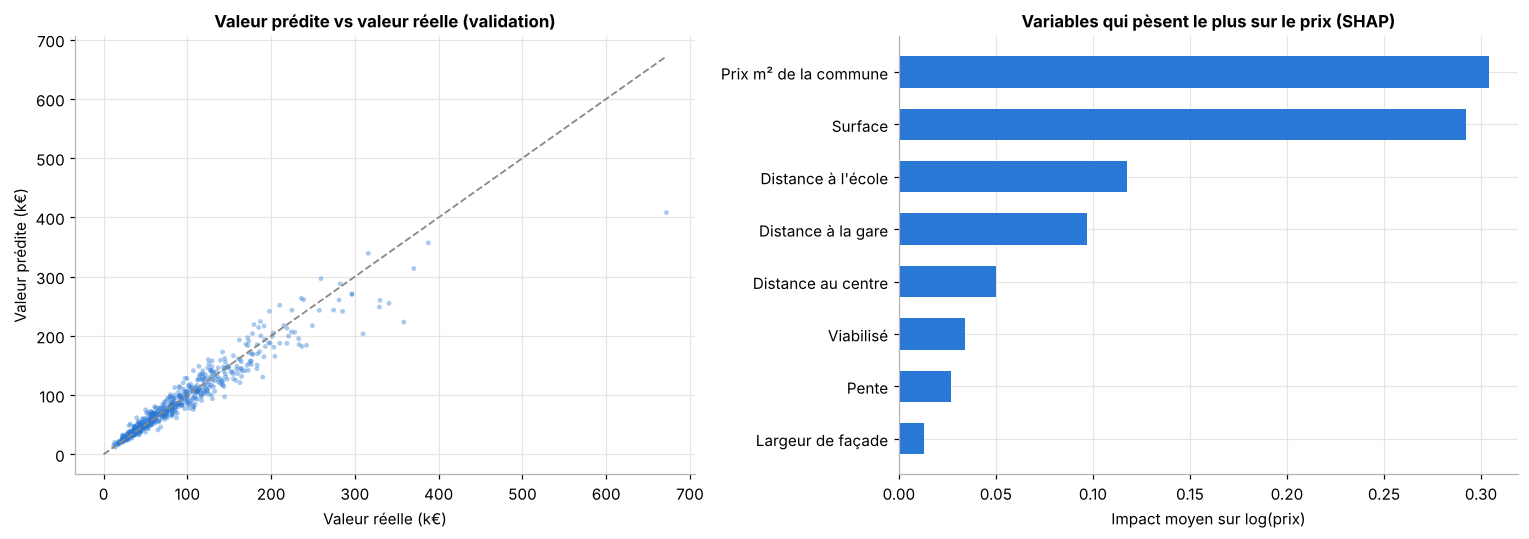

In [9]:
reg = regs["XGBoost"]
pred = reg.predict(M.preparer(vac))

prep = reg.pipe.named_steps["prep"]
Xs = pd.DataFrame(prep.transform(M.preparer(vac)), columns=prep.get_feature_names_out())
Xs = Xs.rename(columns=noms)
explainer = shap.TreeExplainer(reg.pipe.named_steps["reg"])
sv = explainer(Xs)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(vac["valeur_marche"] / 1000, pred / 1000, s=10, alpha=0.4, color=BLEU, edgecolor="none")
lim = [0, max(vac["valeur_marche"].max(), pred.max()) / 1000]
ax[0].plot(lim, lim, color=GRIS, lw=1.2, ls="--")
ax[0].set(title="Valeur prédite vs valeur réelle (validation)", xlabel="Valeur réelle (k€)", ylabel="Valeur prédite (k€)")
imp = pd.Series(np.abs(sv.values).mean(0), index=Xs.columns).sort_values()[-8:]
ax[1].barh(imp.index, imp.values, color=BLEU, height=0.6)
ax[1].set(title="Variables qui pèsent le plus sur le prix (SHAP)", xlabel="Impact moyen sur log(prix)")
plt.tight_layout(); plt.savefig(FIG / "prix_modele.png", bbox_inches="tight"); plt.show()

Sans surprise, le **prix local** (commune), la **surface** et l'**accessibilité** (école, centre) font le prix. La valeur SHAP mesure, pour chaque terrain, de combien chaque variable pousse le prix vers le haut ou vers le bas par rapport à la moyenne.

## 5. Question 3 : combien coûtera la construction en plus ?

Ces surcoûts ne s'apprennent pas, ils se **calculent** à partir de barèmes (ordres de grandeur pour une maison individuelle) :

| Contrainte | Surcoût retenu | Pourquoi |
|---|---|---|
| Zone inondable bleue | 15 000 € | plancher surélevé, matériaux résistants à l'eau |
| Argiles aléa moyen / fort | 6 000 € / 14 000 € | étude de sol G2 obligatoire, fondations plus profondes |
| Pente au-delà de 5 % | 1 800 € par point | terrassement, murs de soutènement |
| Terrain non viabilisé | 20 000 € | raccordement eau, électricité, assainissement |

## 6. La décision : acheter, négocier ou éviter

On combine les trois réponses en un **gain attendu** :

$$\text{gain attendu} = P(\text{constructible}) \times (\text{valeur si constructible} - \text{surcoûts}) + (1 - P) \times \text{valeur agricole} - \text{prix demandé}$$

Règle de décision :
- on n'achète que si la constructibilité est très probable (**P ≥ 80 %**), puisque le but est de construire ;
- **Acheter** si le gain attendu dépasse une marge minimale ;
- **Négocier** si une baisse de prix de 10 % au plus suffirait à atteindre cette marge ;
- **Éviter** sinon.

La marge est choisie sur la **validation** pour maximiser le gain réellement obtenu.

Marge retenue : 6 000 €


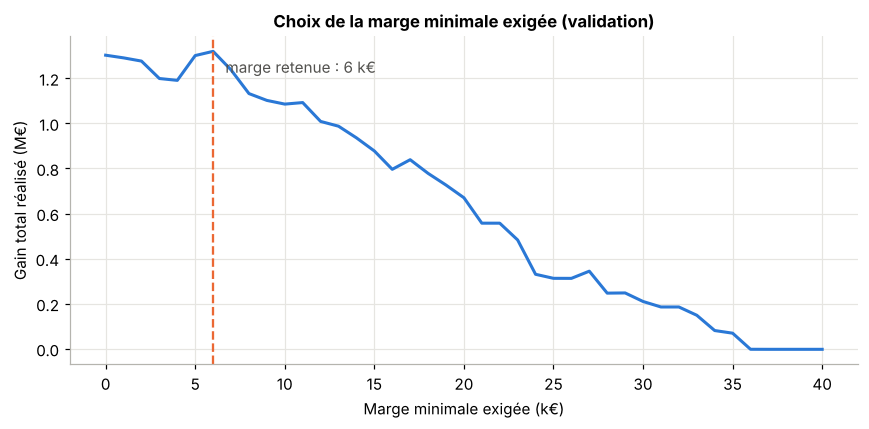

In [10]:
def gain_pred(d):
    X = M.preparer(d)
    return M.gain_attendu(clf.predict_proba(X)[:, 1], reg.predict(X), d["surcouts"], d["surface_m2"], d["prix_demande"])

p_val = clf.predict_proba(Xva)[:, 1]
filtre = p_val >= M.SEUIL_CONSTRUCTIBLE
marge, table_marge = M.choisir_marge(val[filtre], gain_pred(val[filtre]))
print(f"Marge retenue : {marge:,.0f} €".replace(",", " "))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(table_marge["marge"] / 1000, table_marge["gain_total"] / 1e6, color=BLEU, lw=2)
ax.axvline(marge / 1000, color=ORANGE, lw=1.5, ls="--")
ax.annotate(f"marge retenue : {marge/1000:.0f} k€", (marge / 1000, table_marge["gain_total"].max() / 1e6),
            xytext=(8, -14), textcoords="offset points", color="#52514e")
ax.set(title="Choix de la marge minimale exigée (validation)", xlabel="Marge minimale exigée (k€)", ylabel="Gain total réalisé (M€)")
plt.tight_layout(); plt.savefig(FIG / "choix_marge.png", bbox_inches="tight"); plt.show()

## 7. Évaluation finale sur le jeu de test

On compare l'outil à des stratégies qu'un acheteur pourrait suivre sans modèle :

- **Tout acheter** : la référence la plus naïve.
- **Prix au m² bas** : acheter si le prix au m² est 20 % sous la médiane de la commune (« c'est une affaire ! »).
- **Règle PLU + prix bas** : la même chose, mais seulement en zone U/AU et hors zone rouge (l'acheteur prudent qui lit le PLU).
- **Outil ML** : notre règle de décision.
- **Oracle** : acheter exactement les bonnes affaires (le maximum possible, inatteignable).

In [11]:
g_test = gain_pred(test)
p_test = clf.predict_proba(Xte)[:, 1]
prix_bas = test["prix_demande"] / test["surface_m2"] < 0.8 * test["prix_m2_commune"]
regle_plu = test["zone_plu"].isin(["U", "AU"]) & (test["zone_inondable"] != "rouge") & prix_bas
outil = (p_test >= M.SEUIL_CONSTRUCTIBLE) & (g_test >= marge)

strategies = pd.DataFrame([
    M.bilan_strategie(test, np.ones(len(test)), "Tout acheter"),
    M.bilan_strategie(test, prix_bas, "Prix au m² bas"),
    M.bilan_strategie(test, regle_plu, "Règle PLU + prix bas"),
    M.bilan_strategie(test, outil, "Outil ML"),
    M.bilan_strategie(test, test["bonne_affaire"] == 1, "Oracle (maximum possible)"),
])
strategies.to_csv(RES / "strategies_test.csv", index=False)
json.dump({"marge": marge, "seuil_constructible": M.SEUIL_CONSTRUCTIBLE}, open(RES / "parametres.json", "w"), indent=2)
strategies

,strategie,parcelles_achetees,dont_non_constructibles,gain_total_k€,gain_moyen_par_achat_€,taux_bonnes_affaires
0,Tout acheter,1200,578,-19400.0,-16167.0,0.166
1,Prix au m² bas,1005,577,-15359.0,-15283.0,0.161
2,Règle PLU + prix bas,547,123,-6115.0,-11179.0,0.296
3,Outil ML,128,38,1627.0,12711.0,0.664
4,Oracle (maximum possible),199,0,3330.0,16731.0,1.000


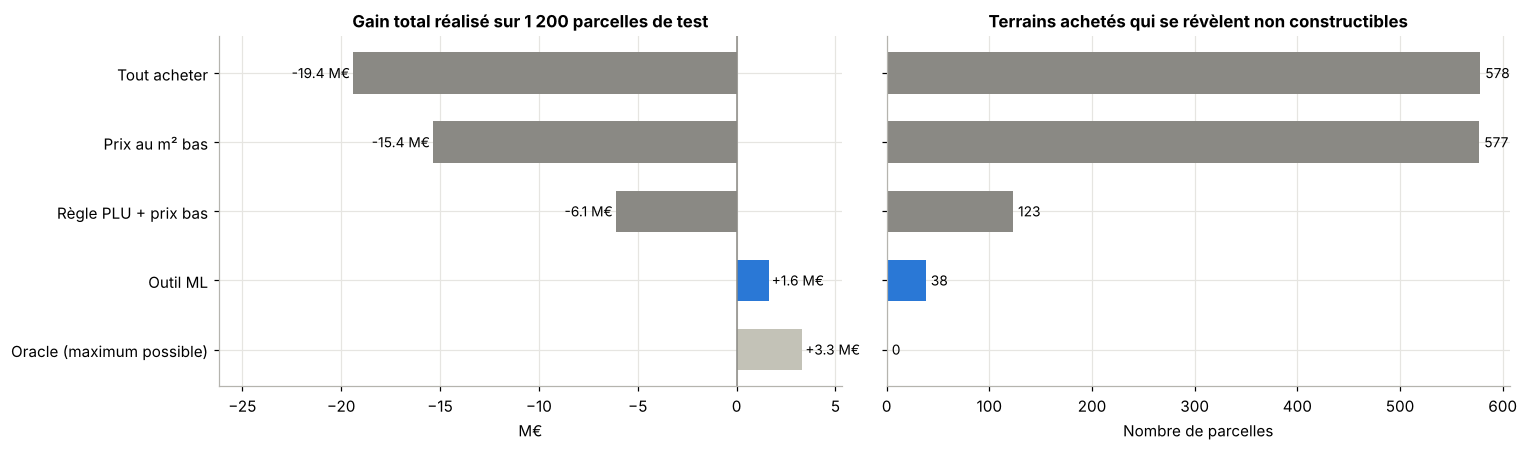

In [12]:
s = strategies.set_index("strategie")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
couleurs = [GRIS, GRIS, GRIS, BLEU, "#c3c2b7"]
ax[0].barh(s.index[::-1], s["gain_total_k€"][::-1] / 1000, color=couleurs[::-1], height=0.6)
ax[0].axvline(0, color=GRIS, lw=1)
for i, v in enumerate(s["gain_total_k€"][::-1] / 1000):
    ax[0].text(v + (0.15 if v >= 0 else -0.15), i, f"{v:+.1f} M€", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax[0].set(title="Gain total réalisé sur 1 200 parcelles de test", xlabel="M€")
ax[0].set_xlim(s["gain_total_k€"].min() / 1000 * 1.35, s["gain_total_k€"].max() / 1000 * 1.6)
ax[1].barh(s.index[::-1], s["dont_non_constructibles"][::-1], color=couleurs[::-1], height=0.6)
for i, v in enumerate(s["dont_non_constructibles"][::-1]):
    ax[1].text(v + 5, i, str(v), va="center", fontsize=9)
ax[1].set(title="Terrains achetés qui se révèlent non constructibles", xlabel="Nombre de parcelles")
ax[1].set_yticklabels([])
plt.tight_layout(); plt.savefig(FIG / "strategies.png", bbox_inches="tight"); plt.show()

**Lecture**
- Acheter sans réfléchir, ou sur le seul critère « prix au m² bas », fait **perdre de l'argent** : les terrains les moins chers sont souvent ceux qui ne sont pas constructibles (le piège de l'annonce agricole au prix d'un terrain à bâtir).
- Lire le PLU limite fortement les dégâts, mais ne suffit pas à gagner de l'argent : il manque les surcoûts et la valeur réelle.
- L'outil ML est la **seule stratégie rentable** parmi celles qu'un acheteur peut appliquer, et capte une bonne part du gain maximal possible.
- Il reste quelques terrains non constructibles achetés malgré une probabilité élevée : ce sont les refus liés à des contraintes invisibles dans les données. D'où la règle d'or : **signer le compromis sous condition suspensive d'obtention du permis**.

## 8. La fiche d'analyse d'une parcelle

Voici ce que l'outil renvoie pour trois parcelles du jeu de test. La même analyse est disponible en ligne de commande avec `python analyser_parcelle.py` (voir le README).

In [13]:
dec = np.where(p_test < M.SEUIL_CONSTRUCTIBLE, "Éviter", M.decider(g_test, test["prix_demande"], marge))
exemples = [
    test[(dec == "Acheter") & (test["bonne_affaire"] == 1)].index[0],
    test[dec == "Négocier"].index[0],
    test[(test["constructible"] == 0) & (test["prix_demande"] > 20 * test["valeur_marche"])].index[0],
]
cols = ["surface_m2", "prix_demande", "zone_plu", "zone_inondable", "alea_argiles", "pente_pct", "viabilise", "prix_m2_commune"]
fiches = []
for i in exemples:
    r = M.analyser(test.loc[[i]], clf, reg, marge)
    fiches.append({**test.loc[i, cols].to_dict(), **r})
pd.DataFrame(fiches, index=["Parcelle A", "Parcelle B", "Parcelle C"]).T

,Parcelle A,Parcelle B,Parcelle C
surface_m2,1295.0,866.0,816.0
prix_demande,51000.0,199300.0,49800.0
zone_plu,U,U,N
zone_inondable,non,non,non
alea_argiles,faible,faible,moyen
pente_pct,1.5,7.7,6.2
viabilise,True,True,False
prix_m2_commune,86.0,269.0,140.0
probabilite_constructible,0.931,0.856,0.025
valeur_estimee_si_constructible,83700.0,224000.0,48000.0


- **Parcelle A** : constructible, prix sous la valeur estimée même après surcoûts : **acheter**.
- **Parcelle B** : intéressante mais un peu chère : l'outil donne le **prix maximum** à proposer au vendeur.
- **Parcelle C** : affichée au prix d'un terrain à bâtir alors que le zonage la rend non constructible : **éviter**.

## 9. Limites et pistes

- **Données simulées** : les ordres de grandeur sont réalistes, mais les résultats chiffrés ne valent que pour ce jeu. Étape suivante : recaler les prix sur les vraies ventes DVF (`python -m src.dvf --dep 33`) et récupérer zonage et risques par parcelle via les API du Géoportail de l'urbanisme et de Géorisques.
- **Surcoûts forfaitaires** : en réalité ils dépendent du projet (taille de la maison, type de fondations). Un devis ou une étude de sol G1 affine le calcul.
- **Pas de dimension temporelle** : le marché foncier évolue (taux d'intérêt, loi Zéro artificialisation nette qui raréfie les terrains constructibles). Un modèle sur DVF devrait intégrer la date de vente.
- **Pistes** : intervalles de prédiction (régression quantile) pour donner une fourchette de prix plutôt qu'une valeur, carte interactive des parcelles, application Streamlit.